## Introduction
Greetings from the Kaggle bot! This is an automatically-generated kernel with starter code demonstrating how to read in the data and begin exploring. Click the blue "Edit Notebook" or "Fork Notebook" button at the top of this kernel to begin editing.

## Exploratory Analysis
To begin this exploratory analysis, first use `matplotlib` to import libraries and define functions for plotting the data. Depending on the data, not all plots will be made. (Hey, I'm just a kerneling bot, not a Kaggle Competitions Grandmaster!)

In [6]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("tongpython/cat-and-dog")

print("Path to dataset files:", path)

Using Colab cache for faster access to the 'cat-and-dog' dataset.
Path to dataset files: /kaggle/input/cat-and-dog


In [7]:
from mpl_toolkits.mplot3d import Axes3D
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt # plotting
import numpy as np # linear algebra
import os # accessing directory structure
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)


In [9]:
for dirname, _, filenames in os.walk(path):
    for filename in filenames:
        print(os.path.join(dirname, filename))


Streaming output truncated to the last 5000 lines.
/kaggle/input/cat-and-dog/training_set/training_set/dogs/dog.3244.jpg
/kaggle/input/cat-and-dog/training_set/training_set/dogs/dog.2373.jpg
/kaggle/input/cat-and-dog/training_set/training_set/dogs/dog.3261.jpg
/kaggle/input/cat-and-dog/training_set/training_set/dogs/dog.614.jpg
/kaggle/input/cat-and-dog/training_set/training_set/dogs/dog.3692.jpg
/kaggle/input/cat-and-dog/training_set/training_set/dogs/dog.1490.jpg
/kaggle/input/cat-and-dog/training_set/training_set/dogs/dog.1805.jpg
/kaggle/input/cat-and-dog/training_set/training_set/dogs/dog.1449.jpg
/kaggle/input/cat-and-dog/training_set/training_set/dogs/dog.3278.jpg
/kaggle/input/cat-and-dog/training_set/training_set/dogs/dog.3748.jpg
/kaggle/input/cat-and-dog/training_set/training_set/dogs/dog.2580.jpg
/kaggle/input/cat-and-dog/training_set/training_set/dogs/dog.2586.jpg
/kaggle/input/cat-and-dog/training_set/training_set/dogs/dog.1996.jpg
/kaggle/input/cat-and-dog/training_set/t

In [10]:
# Verificar la estructura de los datos extraídos
if os.path.exists(path):
    print("Estructura del directorio extraído:")
    for root, dirs, files in os.walk(path):
        level = root.replace(path, '').count(os.sep)
        indent = ' ' * 4 * (level)
        print(f"{indent}{os.path.basename(root)}/")
        subindent = ' ' * 4 * (level + 1)
        # Mostrar solo los primeros 3 archivos de cada carpeta para no saturar la pantalla
        for f in files[:3]:
            print(f"{subindent}{f}")

Estructura del directorio extraído:
cat-and-dog/
    test_set/
        test_set/
            dogs/
                dog.4329.jpg
                dog.4223.jpg
                dog.4253.jpg
            cats/
                cat.4414.jpg
                cat.4420.jpg
                cat.4880.jpg
    training_set/
        training_set/
            dogs/
                dog.3443.jpg
                dog.1942.jpg
                dog.375.jpg
            cats/
                cat.3498.jpg
                cat.891.jpg
                cat.2842.jpg


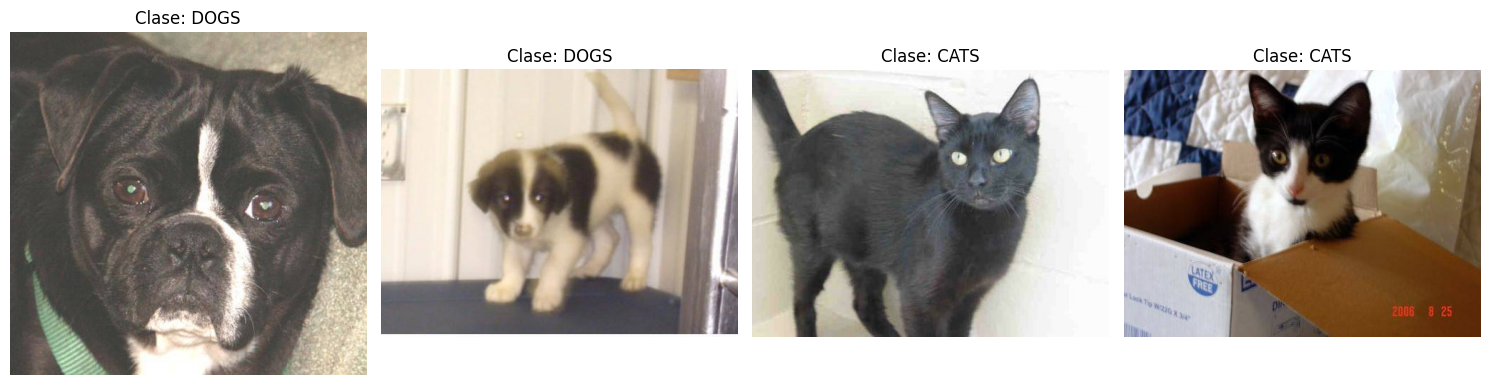

In [11]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import random
import os

def mostrar_ejemplos(carpeta_base):
    clases = ['cats', 'dogs']
    fig, axes = plt.subplots(1, 4, figsize=(15, 5))

    # Apuntamos a la carpeta de entrenamiento dentro de la estructura real
    ruta_entrenamiento = os.path.join(carpeta_base, 'training_set', 'training_set')

    for i in range(4):
        clase_aleatoria = random.choice(clases)
        ruta_clase = os.path.join(ruta_entrenamiento, clase_aleatoria)
        archivos = os.listdir(ruta_clase)
        imagen_aleatoria = random.choice(archivos)
        ruta_imagen = os.path.join(ruta_clase, imagen_aleatoria)

        img = mpimg.imread(ruta_imagen)
        axes[i].imshow(img)
        axes[i].set_title(f"Clase: {clase_aleatoria.upper()}")
        axes[i].axis('off')
    plt.tight_layout()
    plt.show()

# Ejecutar visualización
mostrar_ejemplos(path)

### 1. Preparación de los Datos de Entrenamiento y Validación

Usaremos `ImageDataGenerator` de Keras para reescalar las imágenes y definir la partición del 80% para entrenamiento y 20% para validación de forma automatizada.

In [34]:
import tensorflow as tf
from tensorflow.keras.preprocessing.image import ImageDataGenerator
import os

# Ruta apuntando exactamente a la carpeta que contiene las subcarpetas de clases ('cats' y 'dogs')
base_dir = os.path.join(path, 'training_set', 'training_set')

# Configurar generadores con normalización y partición de validación
datagen = ImageDataGenerator(
    rescale=1./255,
    validation_split=0.2  # 20% para validar el modelo
)

# Cargar imágenes de entrenamiento
train_generator = datagen.flow_from_directory(
    base_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary',
    subset='training'
)

# Cargar imágenes de validación
validation_generator = datagen.flow_from_directory(
    base_dir,
    target_size=(150, 150),
    batch_size=32,
    class_mode='binary',
    subset='validation'
)

Found 6404 images belonging to 2 classes.
Found 1601 images belonging to 2 classes.


### 2. Definición del Modelo CNN

Diseñaremos una arquitectura clásica de clasificación de imágenes: capas convolucionales para extraer características visuales, seguidas de capas densas de clasificación.

In [35]:
from tensorflow.keras import layers, models

model = models.Sequential([
    # Primera capa convolucional
    layers.Conv2D(32, (3, 3), activation='relu', input_shape=(150, 150, 3)),
    layers.MaxPooling2D(2, 2),

    # Segunda capa convolucional
    layers.Conv2D(64, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    # Tercera capa convolucional
    layers.Conv2D(128, (3, 3), activation='relu'),
    layers.MaxPooling2D(2, 2),

    # Capas densas de clasificación
    layers.Flatten(),
    layers.Dense(512, activation='relu'),
    layers.Dropout(0.5),  # Regularización para mitigar sobreajuste
    layers.Dense(1, activation='sigmoid')  # Salida binaria (Gato/Perro)
])

# Compilar el modelo
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

model.summary()

/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_6 (Conv2D)               │ (None, 148, 148, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_6 (MaxPooling2D)  │ (None, 74, 74, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_7 (Conv2D)               │ (None, 72, 72, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_7 (MaxPooling2D)  │ (None, 36, 36, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_8 (Conv2D)               │ (None, 34, 34, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_8 (MaxPooling2D)  │ (None, 17, 17, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_2 (Flatten)             │ (None, 36992)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 512)            │    18,940,416 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 512)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           513 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 19,034,177 (72.61 MB)

 Trainable params: 19,034,177 (72.61 MB)

 Non-trainable params: 0 (0.00 B)

### 3. Entrenamiento del Modelo

Entrenaremos el modelo por 10 épocas monitoreando el comportamiento del error en ambos conjuntos.

In [ ]:
history = model.fit(
    train_generator,
    epochs=10,
    validation_data=validation_generator
)

Epoch 1/10
164/201 ━━━━━━━━━━━━━━━━━━━━ 1:10 2s/step - accuracy: 0.5302 - loss: 0.6889

### 4. Visualización del Margen de Error y Rendimiento

Graficaremos las curvas de Pérdida (Loss) y Precisión (Accuracy) para evaluar el progreso y estimar las desviaciones del modelo.

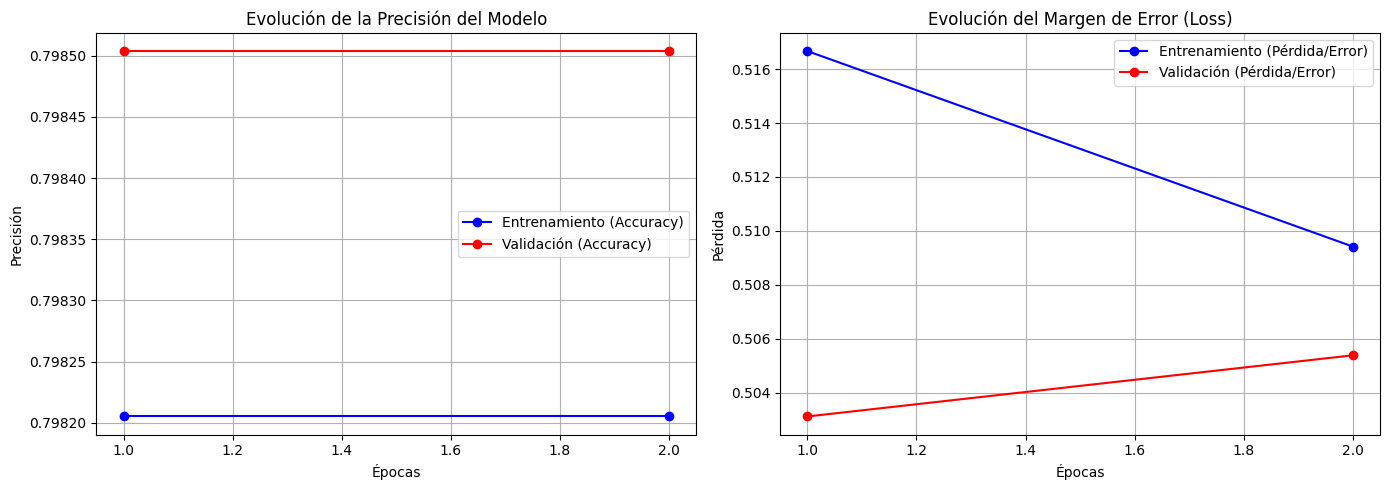

In [33]:
import matplotlib.pyplot as plt

# Recuperar datos del historial de entrenamiento
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
loss = history.history['loss']
val_loss = history.history['val_loss']
epocas = range(1, len(acc) + 1)

# Crear los subplots para las métricas
plt.figure(figsize=(14, 5))

# Subplot de Precisión (Accuracy)
plt.subplot(1, 2, 1)
plt.plot(epocas, acc, 'bo-', label='Entrenamiento (Accuracy)')
plt.plot(epocas, val_acc, 'ro-', label='Validación (Accuracy)')
plt.title('Evolución de la Precisión del Modelo')
plt.xlabel('Épocas')
plt.ylabel('Precisión')
plt.legend()
plt.grid(True)

# Subplot de Pérdida/Error (Loss)
plt.subplot(1, 2, 2)
plt.plot(epocas, loss, 'bo-', label='Entrenamiento (Pérdida/Error)')
plt.plot(epocas, val_loss, 'ro-', label='Validación (Pérdida/Error)')
plt.title('Evolución del Margen de Error (Loss)')
plt.xlabel('Épocas')
plt.ylabel('Pérdida')
plt.legend()
plt.grid(True)

plt.tight_layout()
plt.show()